# Model 2: Global Bayesian GAM / Spline Regression

This notebook recreates the second model:

```text
quantity ~ s(unit_price)
```

The model is still global, meaning all products share one demand curve, but the curve can now be nonlinear.


- Non-linear (Good)
- Not hierarchical (bad)

We will run a bayesian version of GAM. We will use the spline around unit price.

## Notebook setup

The sampling defaults are intentionally smaller than the script defaults so the notebooks are easier to run interactively. Increase `DRAWS`, `TUNE`, or `CHAINS` when you want more stable final inference.


In [25]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep Matplotlib/ArviZ cache files inside the project environment.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib-cache"))

FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

RANDOM_SEED = 123
DRAWS = 500
TUNE = 500
CHAINS = 2
TARGET_ACCEPT = 0.9
CORES = 1


In [26]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from utils.data_loader import load_sales_data

az.style.use("arviz-whitegrid")


In [27]:
sales_df = load_sales_data()
sales_df.head()


,product,quantity,unit_price
0,Standard iPhone Case,444,38.79
1,Standard iPhone Case,477,36.12
2,Standard iPhone Case,656,27.62
3,Standard iPhone Case,507,36.48
4,Standard iPhone Case,513,37.50


In [28]:
sales_df.info()
sales_df.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   product     197 non-null    category
 1   quantity    197 non-null    int64   
 2   unit_price  197 non-null    float64 
dtypes: category(1), float64(1), int64(1)
memory usage: 3.5 KB


,product,quantity,unit_price
count,197,197.000000,197.000000
unique,2,NaN,NaN
top,Standard iPhone Case,NaN,NaN
freq,100,NaN,NaN
mean,NaN,440.137056,46.512437
std,NaN,115.559449,14.660253
min,NaN,160.000000,18.170000
25%,NaN,368.000000,35.030000
50%,NaN,444.000000,39.400000
75%,NaN,518.000000,60.630000


A quick plot helps anchor the modeling problem. We are looking for the relationship between `unit_price` and `quantity`, while remembering that products may have different demand curves.


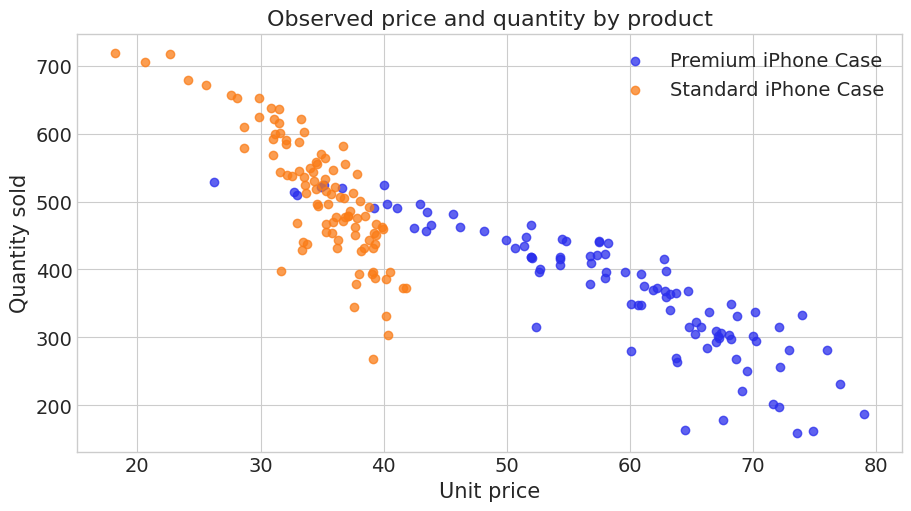

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
for product, group in sales_df.groupby("product", observed=True):
    ax.scatter(group["unit_price"], group["quantity"], alpha=0.75, label=str(product))
ax.set_xlabel("Unit price")
ax.set_ylabel("Quantity sold")
ax.set_title("Observed price and quantity by product")
ax.legend()
plt.show()


In [30]:
def standardise(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    std = float(np.std(values))
    if std == 0:
        raise ValueError("Cannot standardise a variable with zero variance.")
    return (values - mean) / std, mean, std


def prediction_summary(posterior_predictive, original_data, var_name="quantity_obs"):
    draws = posterior_predictive.posterior_predictive[var_name].values
    draws = draws.reshape(-1, draws.shape[-1])
    summary = pd.DataFrame({
        ".pred": np.mean(draws, axis=0),
        ".pred_lower_95": np.quantile(draws, 0.025, axis=0),
        ".pred_lower_66": np.quantile(draws, 0.17, axis=0),
        ".pred_upper_66": np.quantile(draws, 0.83, axis=0),
        ".pred_upper_95": np.quantile(draws, 0.975, axis=0),
    })
    return pd.concat([original_data.reset_index(drop=True), summary], axis=1)


def plot_predictions(predictions, title, facet=False):
    if not facet:
        plot_data = predictions.sort_values("unit_price")
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20, label="95% interval")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35, label="66% interval")
        for product, group in plot_data.groupby("product", observed=True):
            ax.scatter(group["unit_price"], group["quantity"], alpha=0.70, label=str(product))
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black", label="Posterior predictive mean")
        ax.set_xlabel("Unit price")
        ax.set_ylabel("Quantity sold")
        ax.set_title(title)
        ax.legend(fontsize=8)
        plt.show()
        return

    products = list(predictions["product"].cat.categories if hasattr(predictions["product"], "cat") else sorted(predictions["product"].unique()))
    fig, axes = plt.subplots(1, len(products), figsize=(6 * len(products), 5), sharey=True)
    if len(products) == 1:
        axes = [axes]
    for ax, product in zip(axes, products):
        plot_data = predictions[predictions["product"] == product].sort_values("unit_price")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20)
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35)
        ax.scatter(plot_data["unit_price"], plot_data["quantity"], alpha=0.70)
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black")
        ax.set_title(str(product))
        ax.set_xlabel("Unit price")
    axes[0].set_ylabel("Quantity sold")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [31]:
from sklearn.preprocessing import SplineTransformer


## Model idea

A spline turns price into several smooth basis columns. PyMC then learns a coefficient for each basis column:

```text
quantity_i ~ Normal(mu_i, sigma)
mu_i = alpha + beta_1 * basis_1(price_i) + ... + beta_k * basis_k(price_i)
```

That weighted sum produces a flexible smooth curve.


In [32]:
unit_price_raw = sales_df["unit_price"].to_numpy(dtype=float)
quantity = sales_df["quantity"].to_numpy(dtype=float)
unit_price_scaled, price_mean, price_std = standardise(unit_price_raw)

spline_transformer = SplineTransformer(n_knots=6, degree=3, include_bias=False)
spline_basis = spline_transformer.fit_transform(unit_price_scaled.reshape(-1, 1))
spline_basis.shape

(197, 7)

In [33]:
with pm.Model() as model_2:
    spline_data = pm.Data("spline_basis", spline_basis)

    alpha = pm.Normal("alpha", mu=float(np.mean(quantity)), sigma=float(np.std(quantity) * 2))
    spline_coef_scale = pm.HalfNormal("spline_coef_scale", sigma=float(np.std(quantity)))
    spline_coefs = pm.Normal("spline_coefs", mu=0, sigma=spline_coef_scale, shape=spline_basis.shape[1])
    sigma = pm.HalfNormal("sigma", sigma=float(np.std(quantity)))

    mu = alpha + pm.math.dot(spline_data, spline_coefs)
    quantity_obs = pm.Normal("quantity_obs", mu=mu, sigma=sigma, observed=quantity)

    trace_2 = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, cores=CORES, target_accept=TARGET_ACCEPT, random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True,)
    ppc_2 = pm.sample_posterior_predictive(trace_2, var_names=["quantity_obs"], random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True,)


/Users/aryamathew/Documents/learn-business-datascience/hierarchical-models/bayesian_price_elasticity/.venv/lib/python3.9/site-packages/pymc/data.py:434: UserWarning: The `mutable` kwarg was not specified. Before v4.1.0 it defaulted to `pm.Data(mutable=True)`, which is equivalent to using `pm.MutableData()`. In v4.1.0 the default changed to `pm.Data(mutable=False)`, equivalent to `pm.ConstantData`. Use `pm.ConstantData`/`pm.MutableData` or pass `pm.Data(..., mutable=False/True)` to avoid this warning.
  warnings.warn(
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [alpha, spline_coef_scale, spline_coefs, sigma]


Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 16 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [quantity_obs]


## Diagnostics

The spline coefficients are less individually interpretable than the linear slope. Focus on sampler diagnostics and the resulting curve.


In [34]:
az.summary(trace_2, var_names=["alpha", "spline_coef_scale", "sigma"])


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,436.169,71.913,304.473,573.398,5.204,3.689,192.0,370.0,1.02
spline_coef_scale,194.899,47.412,110.796,277.517,1.804,1.277,669.0,483.0,1.00
sigma,50.855,2.616,45.750,55.409,0.092,0.065,814.0,591.0,1.01


/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_45362/230471763.py:2: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


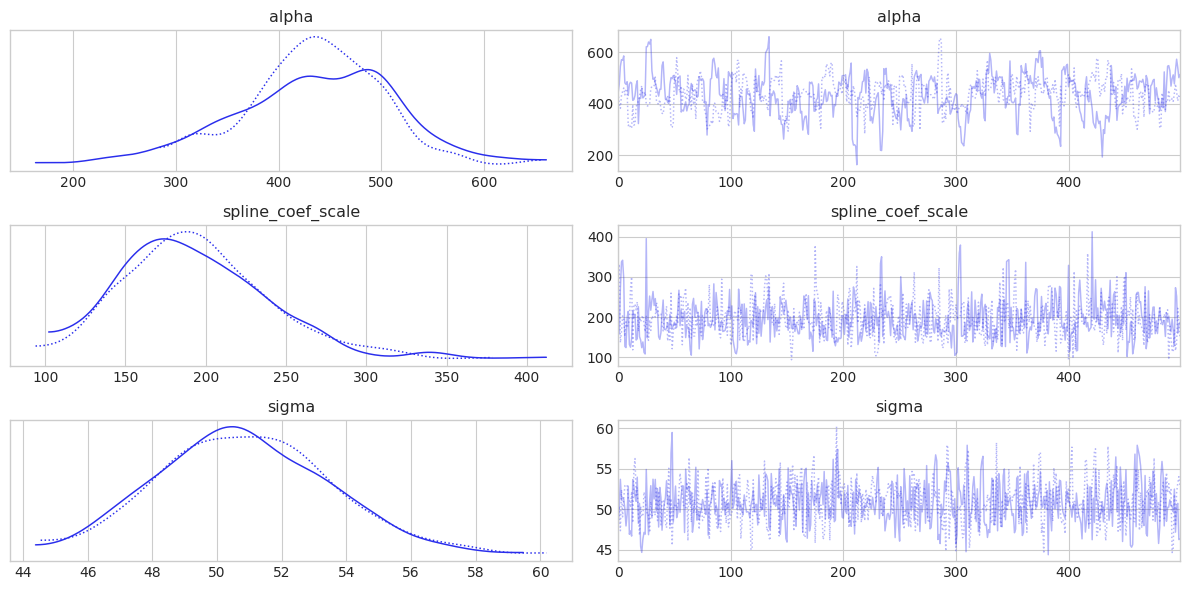

In [35]:
az.plot_trace(trace_2, var_names=["alpha", "spline_coef_scale", "sigma"])
plt.tight_layout()
plt.show()


In [36]:
predictions_2 = prediction_summary(ppc_2, sales_df)
predictions_2.head()


,product,quantity,unit_price,.pred,.pred_lower_95,.pred_lower_66,.pred_upper_66,.pred_upper_95
0,Standard iPhone Case,444,38.79,454.428546,356.060633,404.087611,506.428617,564.965660
1,Standard iPhone Case,477,36.12,490.641196,384.771606,437.972304,539.547677,595.417529
2,Standard iPhone Case,656,27.62,630.826799,531.414599,581.315057,681.461064,736.167877
3,Standard iPhone Case,507,36.48,486.393579,396.061972,437.447384,535.041053,585.343887
4,Standard iPhone Case,513,37.50,468.782473,367.303618,420.939467,515.407365,569.299457


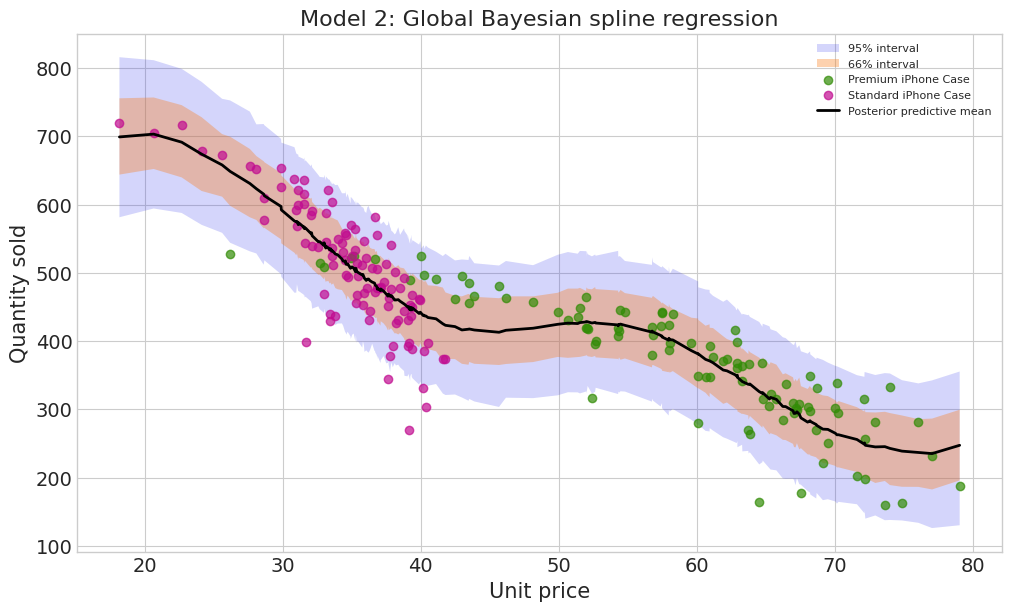

In [37]:
plot_predictions(predictions_2, "Model 2: Global Bayesian spline regression")

- It's not terrible, but it could be better.
- We have more flexibility than before.
- But we still have problems:
    - we haven't added groups into it

In [38]:
trace_2.to_netcdf(MODELS_DIR / "notebook_model2_gam_trace.nc")
predictions_2.to_csv(MODELS_DIR / "notebook_model2_gam_predictions.csv", index=False)
print("Saved notebook Model 2 outputs.")

Saved notebook Model 2 outputs.


## Interpretation

This model can learn a curved demand relationship, which is a major improvement over Model 1. Its weakness is that it still pools every product into one shared curve. If the standard and premium products have different price sensitivity, the global curve can hide that difference.
